# Student Depression prediction.

> This is the dataset: https://www.kaggle.com/datasets/mkhoirulmustaqim/student-depression-detection-dataset
1. Problem Definition
    - We have a large set of data that includes various student features and also corrosponding labels regarding if a student is depressed or not.
    - Our main task is to build a machine learning model that can take students records as an input and predict wheather a student is depressed or not.
    - From the problem definition we can say that this is a binary classification problem. Maybe we will pick some models regarding our problem definition.
       
2. Getting our data ready
    - We will first try to get our data ready. Most importently we will check if all the values are given or not. If there are null values given then we will take action accordingly.
      
3. Features
    - This is the detailed feature dictionary:
    - Gender: The gender of the respondent (e.g., Male/Female).
    - Age: The age of the student in years (ranges from 17 to 28).
    - Family_background: The economic or class status of the family (e.g., Middle class).
    - Relationship_status: The romantic relationship status of the student {"single":0, "in a relationship":1, "complicated": 2}
    - Marital_status: The marital status of the student {"unmarried": 0, "married": 1, "separated": 2} 
    - Living_style: The current living arrangement {"bachelor":0, "family":1}.
    - Current_semester: The semester the student is currently enrolled in.
    - CGPA: Cumulative Grade Point Average (academic performance).
    - friend_circle: Indicates whether the respondent has an active friend circle (Yes/No).
    - Health_condition: General physical health condition (e.g., Good, Normal, Abnormal, Critical).
    - Cost_without_study: Estimated living expenses/costs outside of formal educational fees.
    - Home_division: The home region/division of the respondent (e.g., Dhaka, Chittagong).
    - Depression (Target Variable): Indicates whether the respondent is experiencing depression (Yes/No).
4. Selecting models and tuning the hyper perameters

5. Evaluating our model

6. Saving our model




In [1]:
# Organizing our workflow:
# Importing some basic packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Importing our models
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

# importing modeling tools
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score, GridSearchCV, RandomizedSearchCV

# Evaluation tools
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [2]:
data = pd.read_csv("Student_Depression_Dataset.csv")
data.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [3]:
# Now check the complition of values
data.isna().sum()

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

In [4]:
data.shape, data.size

((4464, 13), 58032)

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 453.5 KB


In [6]:
# As the value of label is string, we have to convert the yes = 1, and no = 0
data["Depression"] = data["Depression"].str.lower().replace({"yes":1, "no":0})
data.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,1
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,1
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,1
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,0
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,1


In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(1), str(8)
memory usage: 453.5+ KB


In [8]:
data["Depression"].value_counts()

Depression
0    3263
1    1201
Name: count, dtype: int64

In [9]:
# Now we have to convert the friend circle to 0 and 1 as those are also yes/no values 
data["friend_circle"] = data["friend_circle"].str.lower().replace({"yes":1, "no":0})
data.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,1,Critical,10113,Chittagong,1
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,1,Abnormal,13815,Chittagong,1
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,0,Abnormal,15450,Dhaka,1
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,0,Good,17413,Dhaka,0
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,0,Abnormal,16693,Dhaka,1


In [10]:
data["Marital_status"].value_counts()

Marital_status
Unmarried    3619
Married       725
Separated     120
Name: count, dtype: int64

In [11]:
data["Health_condition"].value_counts()

Health_condition
Normal      1787
Good        1162
Abnormal     881
Critical     634
Name: count, dtype: int64

In [12]:
data.Gender.value_counts()

Gender
Female    2462
Male      2002
Name: count, dtype: int64

In [13]:
data.Gender = data.Gender.str.lower().replace({"female": 0, "male": 1})
data.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,0,22,Middle class,Single,Unmarried,Bachelor,8,3.43,1,Critical,10113,Chittagong,1
1,1,19,Middle class,Single,Unmarried,Bachelor,2,3.70,1,Abnormal,13815,Chittagong,1
2,1,23,Middle class,Single,Unmarried,Family,8,3.28,0,Abnormal,15450,Dhaka,1
3,1,20,Middle class,Complicated,Unmarried,Family,2,3.77,0,Good,17413,Dhaka,0
4,0,21,Middle class,Single,Unmarried,Family,1,4.00,0,Abnormal,16693,Dhaka,1


## Exploratory data analysis (EDA):

In [14]:
# Now let's try to find a relation between sex and depression rate
pd.crosstab(data["Gender"], data["Depression"])

Depression,0,1
Gender,,
0,1807,655
1,1456,546


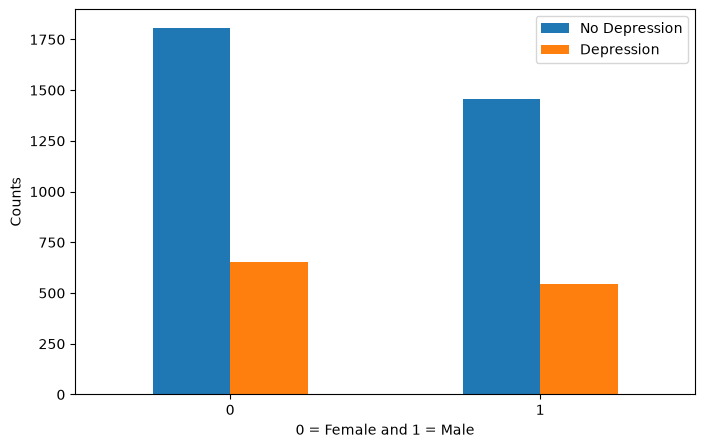

In [15]:
# Now let's plot this in a graph
pd.crosstab(data["Gender"], data["Depression"]).plot(kind="bar", figsize=(8,5))
plt.xlabel("0 = Female and 1 = Male")
plt.xticks(rotation=0)
plt.ylabel("Counts")
plt.legend(["No Depression", "Depression"])
plt.show()

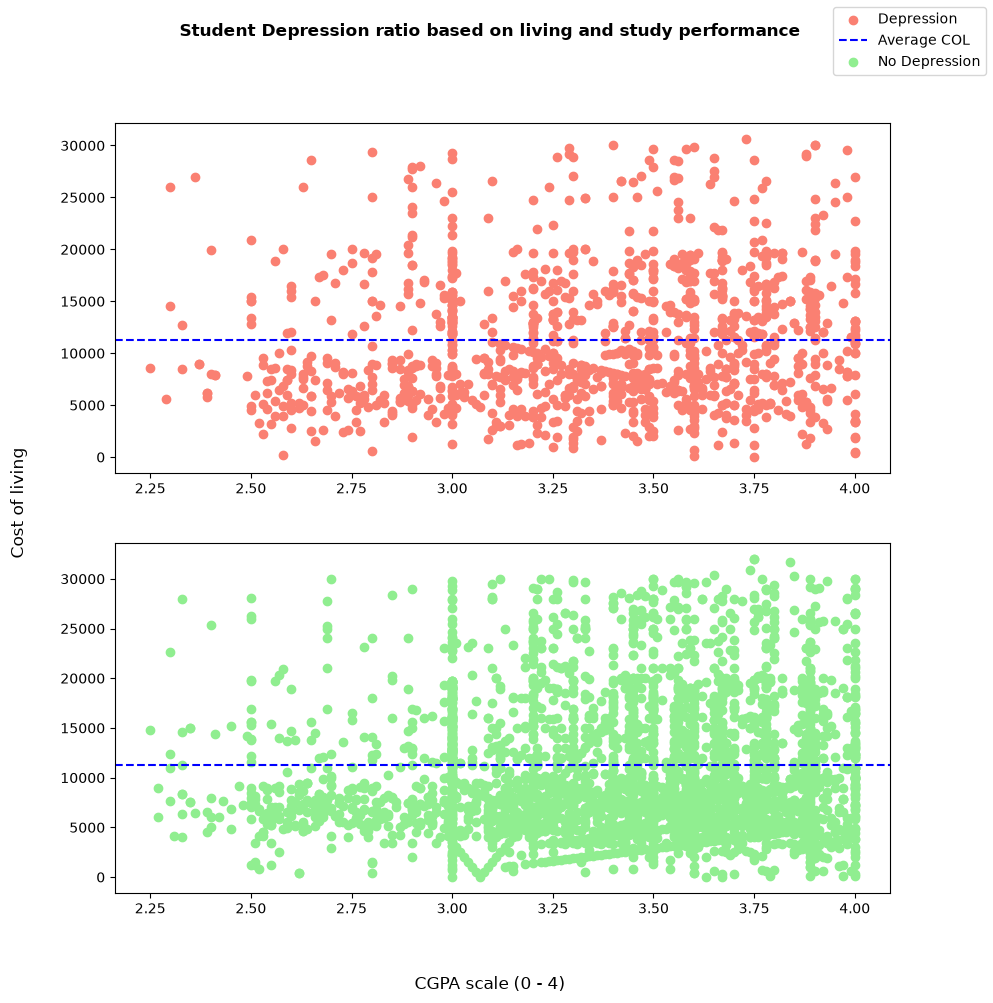

In [16]:
# Now let's compare the marital status of the gender and their depression rate
fig, (ax0, ax1) = plt.subplots(figsize=(10,10),
                                nrows=2,
                                ncols=1)
scatter1 = ax0.scatter(x=data.CGPA[data.Depression == 1],
                      y=data.Cost_without_study[data.Depression ==1],
                      c=["salmon"])
scatter2 = ax1.scatter(x=data.CGPA[data.Depression == 0],
                      y=data.Cost_without_study[data.Depression == 0],
                      c=["lightgreen"])
ax0.axhline(np.mean(data.Cost_without_study), linestyle="--", color="b")
ax1.axhline(np.mean(data.Cost_without_study), linestyle="--", color="b")
fig.legend(["Depression", "Average COL", "No Depression"])
fig.suptitle("Student Depression ratio based on living and study performance", fontweight="bold")
fig.supxlabel("CGPA scale (0 - 4)")
fig.supylabel("Cost of living")
plt.savefig("./plots/student-depression-scatter.png")
plt.show()

### From the visualization we can see some patterns going out there:
> The trend is not fully clear here. There is no relation can be seen between COL and CGPA

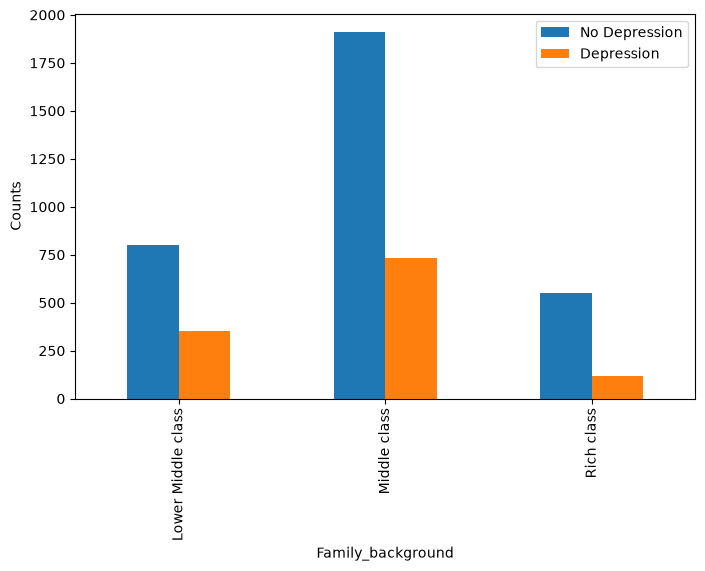

In [17]:
pd.crosstab(data["Family_background"], data["Depression"]).plot.bar(figsize=(8,5))
plt.xlabel("Family_background")
plt.ylabel("Counts")
plt.legend(["No Depression", "Depression"])
plt.show()

In [18]:
data["Marital_status"].value_counts()

Marital_status
Unmarried    3619
Married       725
Separated     120
Name: count, dtype: int64

In [19]:
data["Marital_status"] = data["Marital_status"].str.lower().replace({"unmarried": 0, "married": 1, "separated": 2})
data.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,0,22,Middle class,Single,0,Bachelor,8,3.43,1,Critical,10113,Chittagong,1
1,1,19,Middle class,Single,0,Bachelor,2,3.70,1,Abnormal,13815,Chittagong,1
2,1,23,Middle class,Single,0,Family,8,3.28,0,Abnormal,15450,Dhaka,1
3,1,20,Middle class,Complicated,0,Family,2,3.77,0,Good,17413,Dhaka,0
4,0,21,Middle class,Single,0,Family,1,4.00,0,Abnormal,16693,Dhaka,1


In [20]:
data["Relationship_status"].value_counts()

Relationship_status
Single               2803
In a Relationship    1457
Complicated           204
Name: count, dtype: int64

In [21]:
data["Relationship_status"] = data["Relationship_status"].str.lower().replace({"single":0, "in a relationship":1, "complicated": 2})
data.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,0,22,Middle class,0,0,Bachelor,8,3.43,1,Critical,10113,Chittagong,1
1,1,19,Middle class,0,0,Bachelor,2,3.70,1,Abnormal,13815,Chittagong,1
2,1,23,Middle class,0,0,Family,8,3.28,0,Abnormal,15450,Dhaka,1
3,1,20,Middle class,2,0,Family,2,3.77,0,Good,17413,Dhaka,0
4,0,21,Middle class,0,0,Family,1,4.00,0,Abnormal,16693,Dhaka,1


In [22]:
data["Family_background"].value_counts()

Family_background
Middle class          2642
Lower Middle class    1151
Rich class             671
Name: count, dtype: int64

In [23]:
data["Family_background"] = data["Family_background"].str.lower().replace({"lower middle class":0, "middle class":1, "rich class":2})
data.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,0,22,1,0,0,Bachelor,8,3.43,1,Critical,10113,Chittagong,1
1,1,19,1,0,0,Bachelor,2,3.70,1,Abnormal,13815,Chittagong,1
2,1,23,1,0,0,Family,8,3.28,0,Abnormal,15450,Dhaka,1
3,1,20,1,2,0,Family,2,3.77,0,Good,17413,Dhaka,0
4,0,21,1,0,0,Family,1,4.00,0,Abnormal,16693,Dhaka,1


In [24]:
data["Living_style"].value_counts()

Living_style
Bachelor    2449
Family      2015
Name: count, dtype: int64

In [25]:
data["Living_style"] = data["Living_style"].str.lower().replace({"bachelor":0, "family":1})
data.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,0,22,1,0,0,0,8,3.43,1,Critical,10113,Chittagong,1
1,1,19,1,0,0,0,2,3.70,1,Abnormal,13815,Chittagong,1
2,1,23,1,0,0,1,8,3.28,0,Abnormal,15450,Dhaka,1
3,1,20,1,2,0,1,2,3.77,0,Good,17413,Dhaka,0
4,0,21,1,0,0,1,1,4.00,0,Abnormal,16693,Dhaka,1


In [26]:
data["Health_condition"].value_counts()

Health_condition
Normal      1787
Good        1162
Abnormal     881
Critical     634
Name: count, dtype: int64

In [27]:
data["Health_condition"] = data["Health_condition"].str.lower().replace({"good":0, "normal":1, "abnormal":2, "critical":3})
data.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,0,22,1,0,0,0,8,3.43,1,3,10113,Chittagong,1
1,1,19,1,0,0,0,2,3.70,1,2,13815,Chittagong,1
2,1,23,1,0,0,1,8,3.28,0,2,15450,Dhaka,1
3,1,20,1,2,0,1,2,3.77,0,0,17413,Dhaka,0
4,0,21,1,0,0,1,1,4.00,0,2,16693,Dhaka,1


In [28]:
data["Home_division"].value_counts()

Home_division
Dhaka         1527
Khulna         548
Rajshahi       488
Sylhet         445
Chittagong     400
Rangpur        363
Barisal        355
Mymensingh     338
Name: count, dtype: int64

In [29]:
data["Depression"] = data["Depression"].astype(int)
data["Depression"].dtype

dtype('int64')

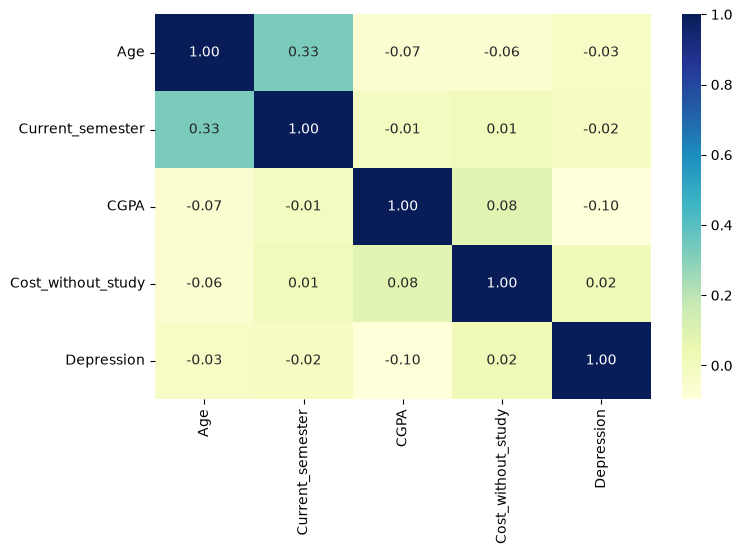

In [30]:
import seaborn as sns
df = data.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(8,5))
ax = sns.heatmap(df, 
                annot=True,
                fmt=".2f",
                cmap="YlGnBu")
plt.savefig("corrilation.png")

In [31]:
# Let's separate features and labels
X = data.drop("Depression", axis=1)
Y = data["Depression"]

In [32]:
X.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division
0,0,22,1,0,0,0,8,3.43,1,3,10113,Chittagong
1,1,19,1,0,0,0,2,3.70,1,2,13815,Chittagong
2,1,23,1,0,0,1,8,3.28,0,2,15450,Dhaka
3,1,20,1,2,0,1,2,3.77,0,0,17413,Dhaka
4,0,21,1,0,0,1,1,4.00,0,2,16693,Dhaka


In [33]:
Y.head()

0    1
1    1
2    1
3    0
4    1
Name: Depression, dtype: int64

In [34]:
# Now let's transform our Home_division colomn to numerical values so that our model can understand
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Feature columsn
feature_columns = ["Home_division"]

# Define our encoder
one_hot = OneHotEncoder()

transformer = ColumnTransformer(
    transformers=[
        ("one_hot", one_hot, feature_columns)
    ],
    remainder="passthrough"
)

X_features = transformer.fit_transform(X)
X_features

array([[0.0, 1.0, 0.0, ..., 1, 3, 10113],
       [0.0, 1.0, 0.0, ..., 1, 2, 13815],
       [0.0, 0.0, 1.0, ..., 0, 2, 15450],
       ...,
       [0.0, 0.0, 0.0, ..., 0, 0, 14066],
       [1.0, 0.0, 0.0, ..., 1, 1, 14338],
       [1.0, 0.0, 0.0, ..., 1, 2, 4000]], shape=(4464, 19), dtype=object)

In [35]:
# Convert X_features into a readable DataFrame using the transformer's column names
df_encoded = pd.DataFrame(X_features, columns=transformer.get_feature_names_out())

# Display the table
df_encoded.head()

,one_hot__Home_division_Barisal,one_hot__Home_division_Chittagong,one_hot__Home_division_Dhaka,one_hot__Home_division_Khulna,one_hot__Home_division_Mymensingh,one_hot__Home_division_Rajshahi,one_hot__Home_division_Rangpur,one_hot__Home_division_Sylhet,remainder__Gender,remainder__Age,remainder__Family_background,remainder__Relationship_status,remainder__Marital_status,remainder__Living_style,remainder__Current_semester,remainder__CGPA,remainder__friend_circle,remainder__Health_condition,remainder__Cost_without_study
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0,22,1,0,0,0,8,3.43,1,3,10113
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1,19,1,0,0,0,2,3.7,1,2,13815
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1,23,1,0,0,1,8,3.28,0,2,15450
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1,20,1,2,0,1,2,3.77,0,0,17413
4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0,21,1,0,0,1,1,4.0,0,2,16693


In [36]:
X_features.shape

(4464, 19)

In [37]:
Y = Y.astype(int)
Y.dtype

dtype('int64')

# Baseline Model Predictions:

In [46]:
import warnings

warnings.filterwarnings("ignore", category=UserWarning, module="joblib")

In [47]:
# Now it's time to make prediction for our models

# Now we have to make a dictionary
models = {
    "RandomForesClassifier": RandomForestClassifier(),
    "KNeighboursClassifier": KNeighborsClassifier(),
    "LogisticRegression": LogisticRegression(max_iter=10000)
}

# Let's make a function for our models to train on
def model_score(models, x, y):
    x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)
    for name, model in models.items():
        model.fit(x_train, y_train)
        print(f"The score for {name} : {model.score(x_test, y_test)*100:.2f}%")

# SO basically we are trying to find the base prediction for all of our model. After that we will start evaluation
model_score(models,X_features, Y)

The score for RandomForesClassifier : 98.88%
The score for KNeighboursClassifier : 72.34%
The score for LogisticRegression : 97.42%


In [39]:
x_train, x_test, y_train, y_test = train_test_split(X_features, Y, test_size=0.2, random_state=42)

# KNeighborsClassifier:

In [40]:
# So in the base line prediction we got 99.44% accuracy in RandomForestClassifier
# Now we will start tuning our hyper perameters for the best result. Then we will see more about evaluation matrics and other stuffs
# Starting with K-Neighbors
train_scores = {}
test_scores = {}
n_neighbors = np.arange(2,30,1)

for n_neighbor in n_neighbors:
    KNN = KNeighborsClassifier(n_neighbors=n_neighbor)
    KNN.fit(x_train, y_train)
    # Now the train and test scores
    train_scores[n_neighbor] = KNN.score(x_train, y_train)
    test_scores[n_neighbor] = KNN.score(x_test, y_test)


In [41]:
df = pd.DataFrame({"train_scores": train_scores, "test_scores": test_scores}).head()
df.head()

,train_scores,test_scores
2,0.844301,0.740202
3,0.851862,0.712206
4,0.795575,0.736842
5,0.801176,0.723404
6,0.773173,0.733483


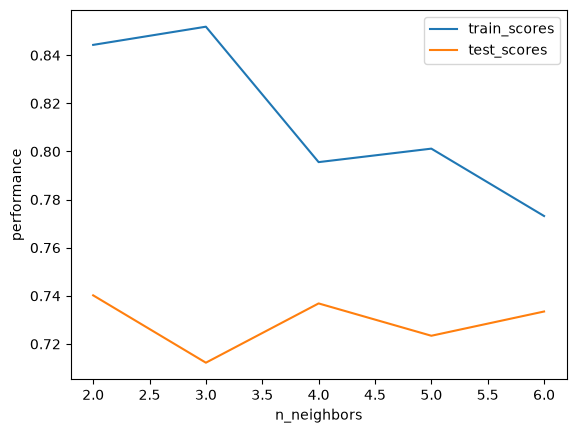

In [42]:
df.plot()
plt.xlabel("n_neighbors")
plt.ylabel("performance")
plt.show()

*The Problem here is that our model is over fitting in smaller values. Like from here we can see that while n_neighbors=3 the test score drops drastically where the train score is at it's peak. It means our model is just memorizing the training dataset, he is not trying to find patterns so that can improve is the test dataset*

In [43]:
# Although we can find the best n_neighbors value using GridSearchCV also we will check what our model performs in different splits
from sklearn.model_selection import StratifiedKFold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Hyper perameter dictionary
parameters = {
    "n_neighbors" : np.arange(2,30,1)
}

# defining our model
KNN = KNeighborsClassifier()

KNN_RSC = RandomizedSearchCV(KNN, param_distributions=parameters, cv=skf, verbose=10, random_state=42)
KNN_RSC.fit(x_train, y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV 1/5; 1/10] START n_neighbors=11.............................................
[CV 1/5; 1/10] END ..............n_neighbors=11;, score=0.697 total time=   0.0s
[CV 2/5; 1/10] START n_neighbors=11.............................................
[CV 2/5; 1/10] END ..............n_neighbors=11;, score=0.714 total time=   0.0s
[CV 3/5; 1/10] START n_neighbors=11.............................................
[CV 3/5; 1/10] END ..............n_neighbors=11;, score=0.718 total time=   0.0s
[CV 4/5; 1/10] START n_neighbors=11.............................................
[CV 4/5; 1/10] END ..............n_neighbors=11;, score=0.710 total time=   0.0s
[CV 5/5; 1/10] START n_neighbors=11.............................................
[CV 5/5; 1/10] END ..............n_neighbors=11;, score=0.696 total time=   0.0s
[CV 1/5; 2/10] START n_neighbors=27.............................................
[CV 1/5; 2/10] END ..............n_neighbors=27;

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'n_neighbors': array([ 2, 3..., 27, 28, 29])}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",10
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In th

In [44]:
KNN_RSC.best_params_

{'n_neighbors': np.int64(2)}

In [45]:
print(f"Best score with our base training and test split: {KNN_RSC.score(x_train, y_train)*100:2f}%")
print(f"Best score with all of the training and test splits: {KNN_RSC.best_score_*100:2f}%")

Best score with our base training and test split: 84.430132%
Best score with all of the training and test splits: 73.368827%


## So with our KNN after tuning the hyperperameters:
> We are able to get a better score in our base trainig and test split(84.4%)

> But in general with 5 fold shuffle the result is almost the same(73.4%)

# LogisticRegression:

In [51]:
# First find the best parameter using GridSearchCV

params = {
    "C": np.logspace(-4,4,20),
    "solver": ["lbfgs", "liblinear", "saga", "sag", "newton-cg"]
}

GSC_CLF = GridSearchCV(LogisticRegression(), cv=5, param_grid=params, verbose=9)

GSC_CLF.fit(x_train, y_train)

Fitting 5 folds for each of 100 candidates, totalling 500 fits
[CV 1/5] END ............C=0.0001, solver=lbfgs;, score=0.727 total time=   0.0s
[CV 2/5] END ............C=0.0001, solver=lbfgs;, score=0.728 total time=   0.0s


C:\Users\ASUS\project_1\Student-Depression-Project\env\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\ASUS\project_1\Student-Depression-Project\env\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://sciki

[CV 3/5] END ............C=0.0001, solver=lbfgs;, score=0.728 total time=   0.0s
[CV 4/5] END ............C=0.0001, solver=lbfgs;, score=0.728 total time=   0.0s
[CV 5/5] END ............C=0.0001, solver=lbfgs;, score=0.727 total time=   0.0s
[CV 1/5] END ........C=0.0001, solver=liblinear;, score=0.727 total time=   0.0s
[CV 2/5] END ........C=0.0001, solver=liblinear;, score=0.728 total time=   0.0s
[CV 3/5] END ........C=0.0001, solver=liblinear;, score=0.728 total time=   0.0s


C:\Users\ASUS\project_1\Student-Depression-Project\env\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\ASUS\project_1\Student-Depression-Project\env\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://sciki

[CV 4/5] END ........C=0.0001, solver=liblinear;, score=0.728 total time=   0.0s
[CV 5/5] END ........C=0.0001, solver=liblinear;, score=0.727 total time=   0.0s
[CV 1/5] END .............C=0.0001, solver=saga;, score=0.727 total time=   0.0s


C:\Users\ASUS\project_1\Student-Depression-Project\env\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\ASUS\project_1\Student-Depression-Project\env\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


... (256 outputs left out)

[CV 2/5] END .............C=10000.0, solver=sag;, score=0.728 total time=   0.0s
[CV 3/5] END .............C=10000.0, solver=sag;, score=0.728 total time=   0.0s


C:\Users\ASUS\project_1\Student-Depression-Project\env\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\ASUS\project_1\Student-Depression-Project\env\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[CV 4/5] END .............C=10000.0, solver=sag;, score=0.728 total time=   0.0s
[CV 5/5] END .............C=10000.0, solver=sag;, score=0.727 total time=   0.0s
[CV 1/5] END .......C=10000.0, solver=newton-cg;, score=0.954 total time=   0.2s
[CV 2/5] END .......C=10000.0, solver=newton-cg;, score=0.961 total time=   0.1s
[CV 3/5] END .......C=10000.0, solver=newton-cg;, score=0.962 total time=   0.1s
[CV 4/5] END .......C=10000.0, solver=newton-cg;, score=0.958 total time=   0.1s
[CV 5/5] END .......C=10000.0, solver=newton-cg;, score=0.952 total time=   0.2s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegression()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': array([1.0000...00000000e+04]), 'solver': ['lbfgs', 'liblinear', ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",9
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see ho

In [52]:
GSC_CLF.best_params_

{'C': np.float64(0.03359818286283781), 'solver': 'newton-cg'}

In [53]:
print(f"Best score according to our test splits: {GSC_CLF.score(x_train, y_train)}")
print(f"Best score according to 5 folds: {GSC_CLF.best_score_}")

Best score according to our test splits: 0.9627555306636797
Best score according to 5 folds: 0.9619149477973007


In [54]:
from sklearn.model_selection import KFold
# OK now let's try finding with randomizedsearchcv
skf = KFold(n_splits=5, shuffle=True, random_state=42)

params = {
    "C": np.logspace(-4,4,20),
    "solver": ["lbfgs", "liblinear", "saga", "sag", "newton-cg"]
}

RSC_CLF = RandomizedSearchCV(LogisticRegression(), param_distributions=params, 
                            cv=skf)
RSC_CLF.fit(x_train, y_train)

C:\Users\ASUS\project_1\Student-Depression-Project\env\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\ASUS\project_1\Student-Depression-Project\env\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\ASUS\project_1\Student-Depression-Project\env\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\ASUS\project_1\Student-Depression-Project\env\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\ASUS\project_1\Student-Depression-Project\env\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the 

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegression()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'C': array([1.0000...00000000e+04]), 'solver': ['lbfgs', 'liblinear', ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_c

In [55]:
print(f"Best score in our test split: {RSC_CLF.score(x_test, y_test)}")
print(f"Best score in our 5 folds: {RSC_CLF.best_score_}")

Best score in our test split: 0.9686450167973124
Best score in our 5 folds: 0.9577171847760084


In [56]:
RSC_CLF.best_params_

{'solver': 'liblinear', 'C': np.float64(11.288378916846883)}

# RandomForestClassifier:

In [61]:
from scipy.stats import randint
from sklearn.model_selection import StratifiedKFold
# Start with GridSearchCV:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

params = {
    "n_estimators": [100, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "max_features": ["sqrt", "log2"],
    "min_samples_leaf": [1, 2, 4],
    "min_samples_split": [2, 5, 10],
}

# Let's try to find the best parameter
GSC_RCl = GridSearchCV(RandomForestClassifier(), param_grid=params, cv=skf, verbose=10) 

# Fit the model
GSC_RCl.fit(x_train, y_train)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
[CV 1/5; 1/216] START max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100
[CV 1/5; 1/216] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100;, score=0.987 total time=   0.5s
[CV 2/5; 1/216] START max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100
[CV 2/5; 1/216] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100;, score=0.985 total time=   0.5s
[CV 3/5; 1/216] START max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100
[CV 3/5; 1/216] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100;, score=0.983 total time=   0.5s
[CV 4/5; 1/216] START max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100
[CV 4/5; 1/216] END max_depth=None, ma

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricev

In [62]:
GSC_RCl.best_params_

{'max_depth': None,
 'max_features': 'log2',
 'min_samples_leaf': 2,
 'min_samples_split': 5,
 'n_estimators': 100}

In [63]:
print(f"Best score in our train, test split: {GSC_RCl.score(x_train, y_train)}")
print(f"Best score in 5 fold split: {GSC_RCl.best_score_}")

Best score in our train, test split: 0.9932791935032204
Best score in 5 fold split: 0.9868382597794362


### We are sticking with RandomForest Classifier
> Cause it got the best accuracy ever then other two

- Now it's time to evaluate our model in different scoring perameters:
- As it is a clasiification problem we are going to evaluate:
  - ROC AUC (Roc curve)
  - COnfusion Matrix
  - Classification Report

# ROC Area under Curve:

In [75]:
# Now as we have the best parameters known, We can create our model
model = RandomForestClassifier(max_depth=None, 
                               max_features='log2', 
                               min_samples_leaf=2, 
                               min_samples_split=5,
                              n_estimators=100)
model.fit(x_train, y_train)
y_preds = model.predict(x_test)
y_preds[:10]

array([0, 1, 0, 0, 0, 0, 1, 0, 0, 1])

In [77]:
np.array(y_test)[:10]

array([0, 1, 0, 0, 0, 0, 1, 0, 0, 1])

In [78]:
# Let's see the AUC score;
print(f"AUC Score: {roc_auc_score(y_test, y_preds)}")

AUC Score: 0.982532751091703


<Figure size 500x400 with 0 Axes>

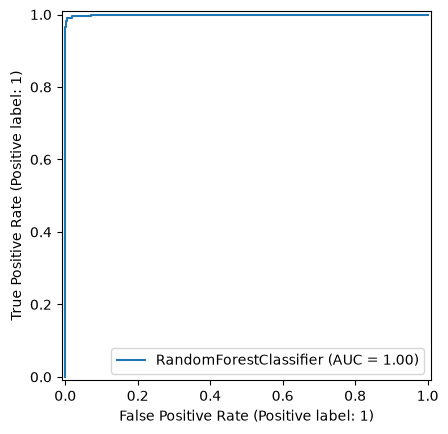

In [82]:
from sklearn.metrics import RocCurveDisplay
plt.figure(figsize=(5,4))
RocCurveDisplay.from_estimator(model, x_test, y_test)
plt.show();

# Confusion Metrics:

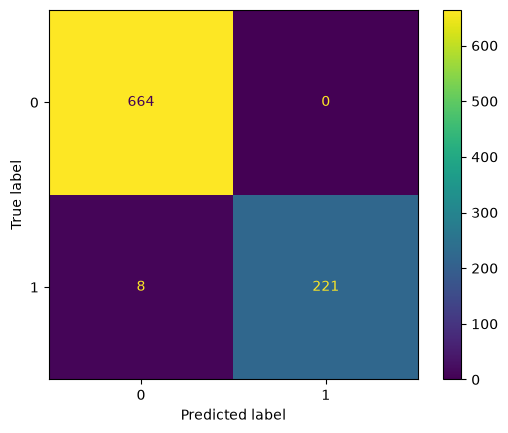

In [86]:
# Now, lets Check the confusion matrix:
confusion = confusion_matrix(y_test, y_preds)
ConfusionMatrixDisplay(confusion).plot()
plt.savefig("confusion-metrics.png")

# Classification Report:

In [89]:
print(classification_report(y_test, y_preds))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       664
           1       1.00      0.97      0.98       229

    accuracy                           0.99       893
   macro avg       0.99      0.98      0.99       893
weighted avg       0.99      0.99      0.99       893



# Although as we know that these are the classification report for one train test split we have to calculate with different train test splits
**Cross validation for:**
- Accuracy
- Precision
- recall
- f1-score

## Accuracy:

In [93]:
cross_val_accuracy = cross_val_score(model, X_features, Y, cv=5, scoring="accuracy")
print(f"Accuracy in 5 fold: {np.mean(cross_val_accuracy)*100:.2f}%")

Accuracy in 5 fold: 97.45%


In [94]:
cross_val_precision = cross_val_score(model, X_features, Y, cv=5, scoring="precision")
print(f"Precision in 5 fold: {np.mean(cross_val_precision)*100:.2f}%")

Precision in 5 fold: 98.24%


In [95]:
cross_val_f1 = cross_val_score(model, X_features, Y, cv=5, scoring="f1")
print(f"F1 score in 5 fold: {np.mean(cross_val_f1)*100:.2f}%")

F1 score in 5 fold: 95.48%


In [96]:
cross_val_recall = cross_val_score(model, X_features, Y, cv=5, scoring="recall")
print(f"Recall in 5 fold: {np.mean(cross_val_recall)*100:.2f}%")

Recall in 5 fold: 93.34%


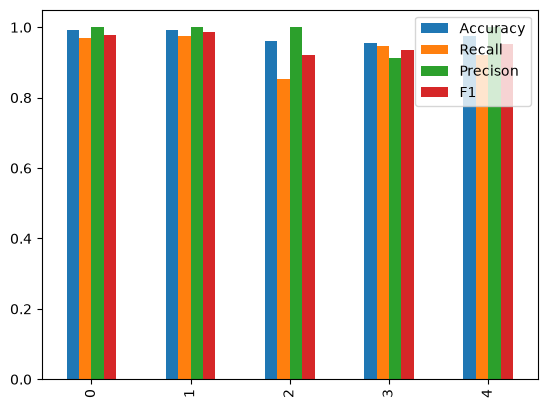

In [98]:
# Now let's plot this:
scoring_dict = {
    "Accuracy": cross_val_accuracy,
    "Recall" : cross_val_recall,
    "Precison": cross_val_precision,
    "F1": cross_val_f1
}
pd.DataFrame(scoring_dict).plot.bar()
plt.savefig("final_scoring.png")

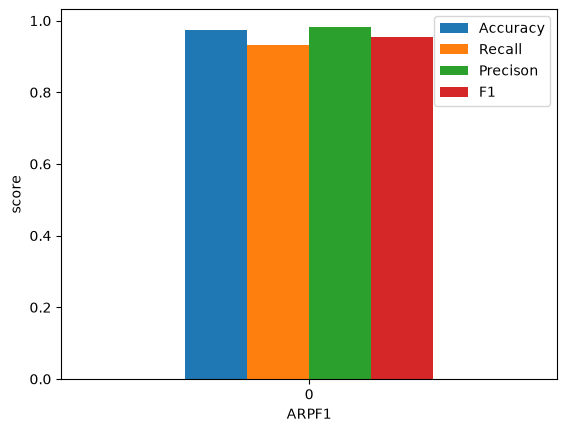

In [108]:
# for the mean ones 
scoring_mean ={
    "Accuracy": np.mean(cross_val_accuracy),
    "Recall" : np.mean(cross_val_recall),
    "Precison": np.mean(cross_val_precision),
    "F1": np.mean(cross_val_f1)
    
}
pd.DataFrame(scoring_mean, index=[0]).plot.bar()
plt.xticks(rotation=0)
plt.xlabel("ARPF1")
plt.ylabel("score")
plt.savefig("Mean_scoring.png")
plt.show()